# Modellierung

## Init

In [42]:
import pandas as pd

# Load the dataset
file_path = '../../data/processed/sickness_table.csv'
df = pd.read_csv(file_path, index_col=0)

# Convert date column to datetime
df.index = pd.to_datetime(df.index)

# Datenselektierung

In [43]:
display(df.head())

,n_sick,calls,n_duty,n_sby,sby_need,dafted,unix_ts_date,needed_personal,sby_used_percent,personal_calculated_by_calls,...,month,day_of_week,day_of_month,week_of_year,day_of_year,is_weekend,is_holiday,tavg,tmin,tmax
date,,,,,,,,,,,,,,,,,,,,,
2016-04-01,73,8154.0,1700,90,4.0,0.0,1459468800,1704.0,0.044444,1734.893617,...,4,4,1,13,92,False,False,8.3,5.0,13.1
2016-04-02,64,8526.0,1700,90,70.0,0.0,1459555200,1770.0,0.777778,1814.042553,...,4,5,2,13,93,True,False,9.9,1.3,16.4
2016-04-03,68,8088.0,1700,90,0.0,0.0,1459641600,1700.0,0.000000,1720.851064,...,4,6,3,13,94,True,False,13.1,6.1,19.1
2016-04-04,71,7044.0,1700,90,0.0,0.0,1459728000,1700.0,0.000000,1498.723404,...,4,0,4,14,95,False,False,15.2,9.5,20.6
2016-04-05,63,7236.0,1700,90,0.0,0.0,1459814400,1700.0,0.000000,1539.574468,...,4,1,5,14,96,False,False,16.0,8.4,22.7


In [44]:
print(df.columns)

Index(['n_sick', 'calls', 'n_duty', 'n_sby', 'sby_need', 'dafted',
       'unix_ts_date', 'needed_personal', 'sby_used_percent',
       'personal_calculated_by_calls',
       'personal_calculated_by_calls_not_below_n_duty',
       'sby_need_calculated_by_calls', 'calls_per_duty', 'call_stress', 'year',
       'month', 'day_of_week', 'day_of_month', 'week_of_year', 'day_of_year',
       'is_weekend', 'is_holiday', 'tavg', 'tmin', 'tmax'],
      dtype='object')


In [45]:

# List der Spalten, die nicht benutzt werden sollen, da sie u. a. zur Anwendungszeit nicht zur Verfügung stehen und daher auch nicht als Features genutzt werden können oder
excluded_columns = ["sby_need", "dafted", "n_sick", "calls", "call_stress", "sby_used_percent", "calls_per_duty", "date", "needed_personal"]

usable_columns = list(set(df.columns) - set(excluded_columns))

#Overwrite usable_columns to force certain scenario
usable_columns = ["unix_ts_date", "day_of_week", "day_of_month", "day_of_year"]                                                                                               # R2: 44% (this and all below only works for shuffled data)
#usable_columns = ["unix_ts_date", "year", "month", "week_of_year", "day_of_year", "is_weekend", "is_holiday", "day_of_week"]           # R2: 51,1% 
#usable_columns = ["month", "day_of_year"]                                                                                      # R2: 22%
#usable_columns = ["year", "day_of_year"]                                                                                       # R2: 44%
#usable_columns = ["unix_ts_date", "month"]                                                                                     # R2: 45%
#usable_columns = ["unix_ts_date", "month", "day_of_year"]                                                                      # R2: 49%
#usable_columns = ["unix_ts_date", "is_weekend"]                                                                                 # R2: 49%
#usable_columns = ["unix_ts_date", "is_weekend", "is_holiday", "day_of_week", "month"]                                                                   # R2: 49%
#usable_columns = ["unix_ts_date", "is_weekend", "calls_ma_7_lag_30"]                                                                   # R2: 
#usable_columns = ["calls_ma_8_lag_1", "unix_ts_date"]
#usable_columns = ["week_of_year", "day_of_week", "is_holiday", "is_weekend"]

target_column = 'calls' #'sby_need'

print("Usable columns:", usable_columns)

Usable columns: ['unix_ts_date', 'day_of_week', 'day_of_month', 'day_of_year']


In [46]:
from sklearn.model_selection import train_test_split


# Prepare features and target
X = df[usable_columns]

#X = df[['n_duty', 'season', 'month', 'day_of_week', 'is_holiday', 'is_weekend']] #auf faktoren beschränkt, die man zu dem Zeitpunkt der Planung wissen kann

y = df[target_column]

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False) # shuffle = False um Daten Ordnung beizubehalten

# Modellierungvergleiche

In [47]:
# Modelle für Nutzung

from sklearn.ensemble import StackingRegressor, RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.ensemble import BaggingRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C

# Zusätzliche Modelle, die nicht aus sklearn stammen
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

In [48]:
models = {
    # 'StackingRegressor': StackingRegressor(
    #     estimators=[
    #         ('lr', LinearRegression()),
    #         ('dt', DecisionTreeRegressor(max_depth=10, min_samples_split=10, min_samples_leaf=5)),
    #         ('svr', SVR(C=10, kernel='rbf', gamma='scale'))
    #     ],
    #     final_estimator=Ridge(alpha=1.0),
    #     cv=5,
    #     n_jobs=-1
    # ),
    
    # 'StackingRegressor_2': StackingRegressor(
    #     estimators=[
    #         ('gb', GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=4, subsample=0.8, random_state=42)),
    #         ('nn', MLPRegressor(hidden_layer_sizes=(100, 50), activation='relu', solver='adam', max_iter=1500, random_state=42)),
    #         ('knn', KNeighborsRegressor(n_neighbors=7, weights='distance', p=2))
    #     ],
    #     final_estimator=Ridge(alpha=1.0),
    #     cv=5,
    #     n_jobs=-1
    # ),
    
    'Linear Regression': LinearRegression(),
    
    # 'Decision Tree': DecisionTreeRegressor(
    #     max_depth=10, 
    #     min_samples_split=10, 
    #     min_samples_leaf=5, 
    #     random_state=42
    # ),
    
    'Random Forest': RandomForestRegressor(
        #n_estimators=200, 
        #max_depth=10, 
        #min_samples_split=10, 
        #min_samples_leaf=5, 
        #bootstrap=True, 
        #random_state=42, 
        #n_jobs=-1
    ),
    
    'Gradient Boosting': GradientBoostingRegressor(
        #n_estimators=200, 
        #learning_rate=0.05, 
        #max_depth=4, 
        #subsample=0.8, 
        #random_state=42
    ),
    
    # 'Support Vector Machine': SVR(
    #     C=10, 
    #     kernel='rbf', 
    #     gamma='scale'
    # ),
    
    #'K-Nearest Neighbors': KNeighborsRegressor(n_neighbors=7, weights='distance', p=2),
    
    'Lasso Regression': Lasso(
        alpha=0.01, 
        max_iter=1000, 
        random_state=42
    ),
    
    'Ridge Regression': Ridge(
        alpha=1.0, 
        random_state=42
    ),
    
    'XGBoost': XGBRegressor(
        #n_estimators=200, 
        #learning_rate=0.05, 
        #max_depth=4, 
        #subsample=0.8, 
        #colsample_bytree=0.8, 
        #random_state=42, 
        #n_jobs=-1
    ),
    
    # # Polynomial Regression
    # 'Polynomial Regression (8)': Pipeline([
    #     ('poly', PolynomialFeatures(degree=8)),
    #     ('linear', LinearRegression())
    # ]),
    
    # 'Polynomial Ridge Regression (8)': Pipeline([
    #     ('poly', PolynomialFeatures(degree=8)),
    #     ('ridge', Ridge(alpha=1.0))
    # ]),
    'LightGBM': LGBMRegressor(random_state=42),
    # 'Bagging Regressor': BaggingRegressor(
    #     n_estimators=50,
    #     random_state=42,
    #     n_jobs=-1
    # ),
    
    # 'HistGradient Boosting': HistGradientBoostingRegressor(
    #     loss='absolute_error',
    #     learning_rate=0.05,
    #     max_iter=100,
    #     max_depth=4,
    #     random_state=42
    # )
}


In [49]:
import numpy as np
import time
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.preprocessing import MinMaxScaler


def compare_regression_models(models, X_train, y_train, X_test, y_test, print_results : bool = False, sorted_by = "R2"):

    # Train and evaluate each model
    results = {}


    for model_name, model in models.items():

        start_time = time.time()
        model.fit(X_train, y_train)
        end_time = time.time() 

        start_time_pred = time.time()
        y_pred = model.predict(X_test)
        end_time_pred = time.time() 

        results[model_name] = {
            "MAE" : mean_absolute_error(y_test, y_pred),
            "MSE" : mean_squared_error(y_test, y_pred),
            "RMSE" : np.sqrt(mean_squared_error(y_test, y_pred)),
            "R2" : r2_score(y_test, y_pred),
            "MAPE" : mean_absolute_percentage_error(y_test, y_pred),
            "Training time (s)" : end_time - start_time,
            "Prediction time (s)" : end_time_pred - start_time_pred,
        }
        
        if print_results:
            print(f'{model_name} - ' + ', '.join(f'{key}: {value}' for key, value in results[model_name].items()))


    results_df = pd.DataFrame(results).T

    results_df_sorted = results_df.sort_values(by=sorted_by, ascending=False)

    return results_df_sorted

#######

results_df_sorted = compare_regression_models(models, X_train, y_train, X_test, y_test)

display(results_df_sorted)

# Select the best model
best_model_name = results_df_sorted.index[0]
best_model_results = results_df_sorted.loc[best_model_name]

print(f'Best Model: {best_model_name}')
print(best_model_results)


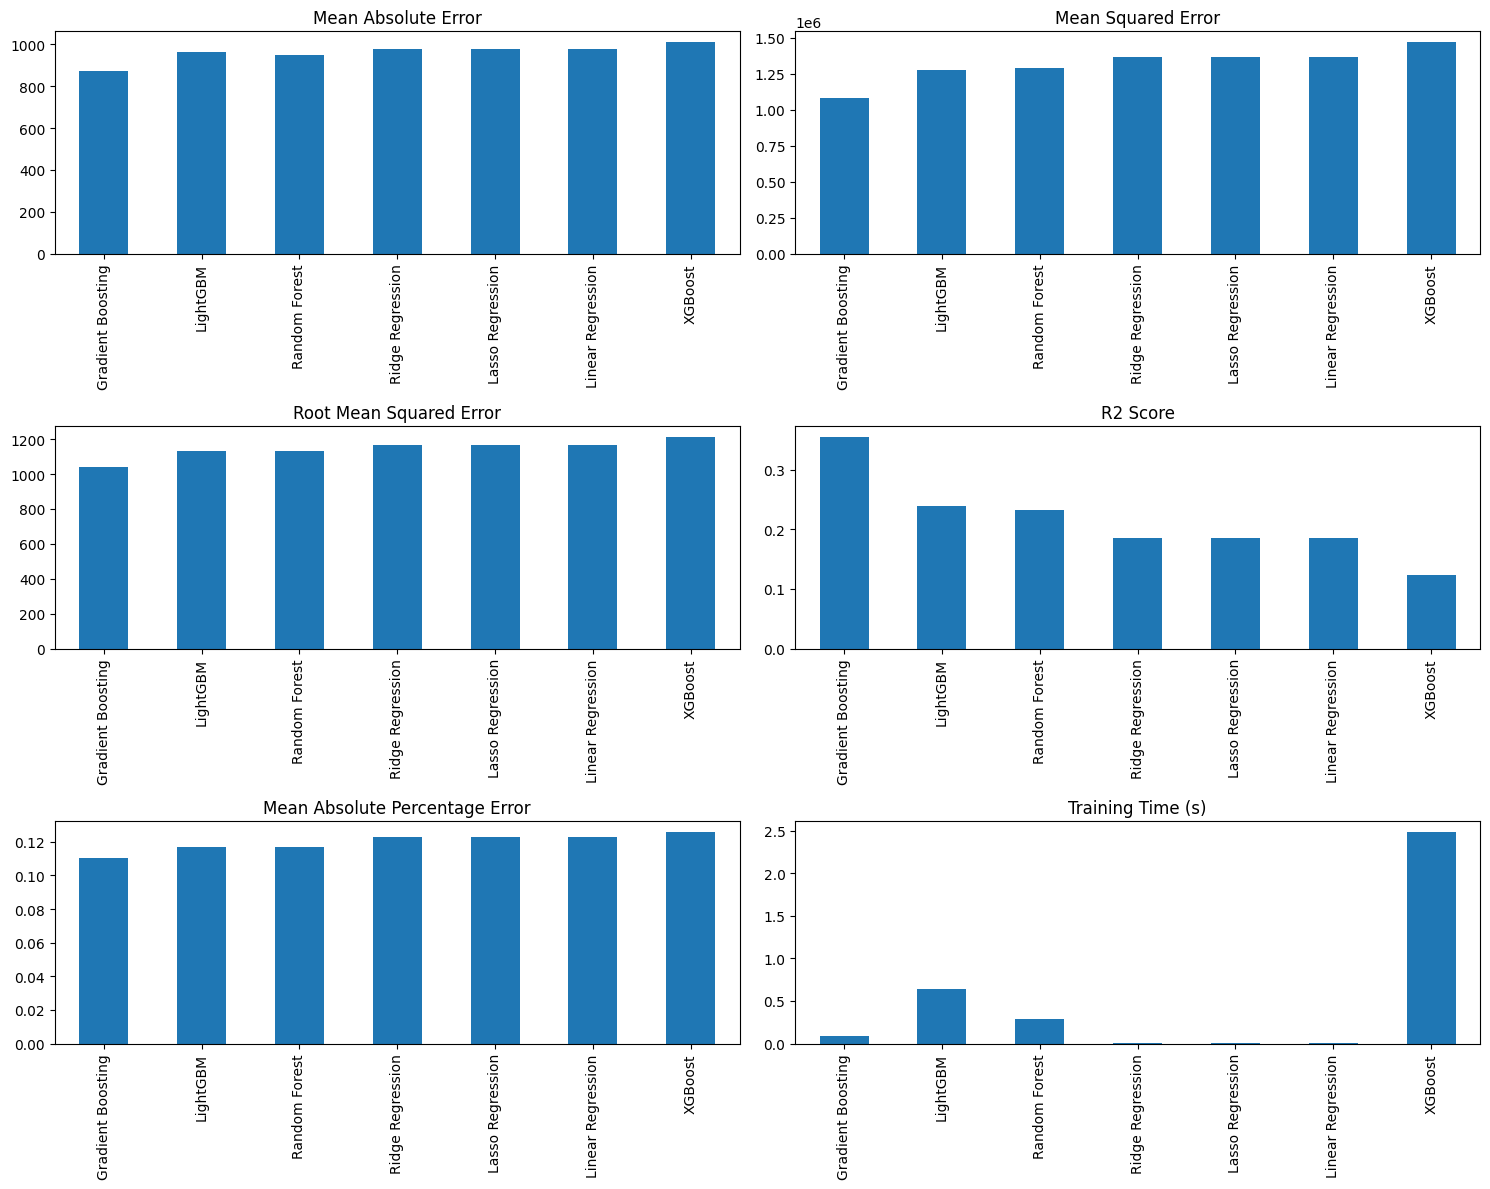

In [28]:
import matplotlib.pyplot as plt

# Visualize the results
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
results_df_sorted['MAE'].plot(kind='bar', ax=axes[0, 0], title='Mean Absolute Error')
results_df_sorted['MSE'].plot(kind='bar', ax=axes[0, 1], title='Mean Squared Error')
results_df_sorted['RMSE'].plot(kind='bar', ax=axes[1, 0], title='Root Mean Squared Error')
results_df_sorted['R2'].plot(kind='bar', ax=axes[1, 1], title='R2 Score')
results_df_sorted['MAPE'].plot(kind='bar', ax=axes[2, 0], title='Mean Absolute Percentage Error')
results_df_sorted['Training time (s)'].plot(kind='bar', ax=axes[2, 1], title='Training Time (s)')
plt.tight_layout()
plt.show()

Final Evaluation of the Best Model (Gradient Boosting):
MAE: 969.5234379410177, MSE: 1334368.2729045576, RMSE: 1155.148593430541, R2: 0.20442896063855964


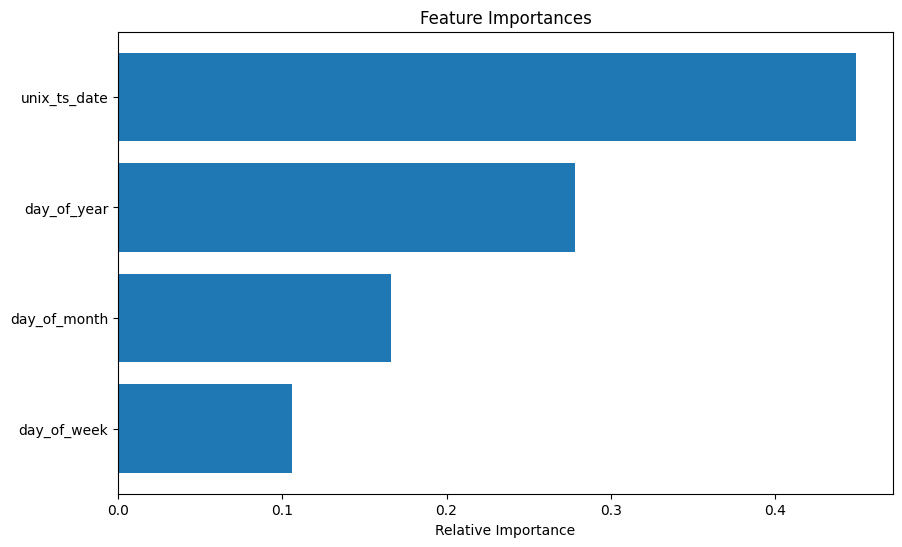

In [29]:
from sklearn.model_selection import GridSearchCV

# If further fine-tuning is needed, you can perform hyperparameter tuning on the best model
if best_model_name == 'Random Forest':
    param_grid = {
        'n_estimators': [100, 200],
        'max_depth': [10, 20, None],
        'min_samples_split': [2, 5]
    }
    grid_search = GridSearchCV(RandomForestRegressor(random_state=42), param_grid, cv=5, scoring='r2')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
elif best_model_name == 'Gradient Boosting':
    param_grid = {
        'n_estimators': [100, 200],
        'learning_rate': [0.01, 0.1, 0.2],
        'max_depth': [3, 5, 7]
    }
    grid_search = GridSearchCV(GradientBoostingRegressor(random_state=42), param_grid, cv=5, scoring='r2')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
elif best_model_name == 'XGBoost':
    param_grid = {
        'n_estimators': [100, 200],
        'learning_rate': [0.01, 0.1, 0.2],
        'max_depth': [3, 5, 7]
    }
    grid_search = GridSearchCV(XGBRegressor(random_state=42), param_grid, cv=5, scoring='r2')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_

elif best_model_name == 'Lasso Regression':

    param_grid = {
        'alpha': [0.001, 0.01, 0.1, 1, 10, 100],  # Verschiedene Werte für den Regularisierungsparameter
        'max_iter': [1000, 5000, 10000],          # Maximale Anzahl an Iterationen
        'tol': [1e-4, 1e-3, 1e-2]                 # Toleranz für die Optimierung
    }

    grid_search = GridSearchCV(Lasso(random_state=42), param_grid=param_grid, cv=5, n_jobs=-1, scoring='r2', verbose=1)
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_

#elif best_model_name == 'StackingRegressor':
    # Do new stuff here
else:
    print("No Hyperparameter-Tuning because there is no template")
    best_model = models[best_model_name]

# Add similar tuning for other models if needed

# Train the best model with the entire dataset
best_model.fit(X_train, y_train)
y_pred_best = best_model.predict(X_test)

# Final evaluation of the best model
final_mae = mean_absolute_error(y_test, y_pred_best)
final_mse = mean_squared_error(y_test, y_pred_best)
final_rmse = np.sqrt(final_mse)
final_r2 = r2_score(y_test, y_pred_best)

print(f'Final Evaluation of the Best Model ({best_model_name}):')
print(f'MAE: {final_mae}, MSE: {final_mse}, RMSE: {final_rmse}, R2: {final_r2}')

features = X.columns

if hasattr(best_model, "feature_importances_"):
    # Feature Importance for the best model
    importances = best_model.feature_importances_
elif hasattr(best_model, "coef_"):
    importances = np.argsort(np.abs(best_model.coef_))
else: 
    from sklearn.inspection import permutation_importance
    perm_importance = permutation_importance(best_model, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1)
    importances = perm_importance.importances_mean
        

indices = np.argsort(importances)
plt.figure(figsize=(10, 6))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()

In [30]:
def calculate_custom_personal_metrics(df: pd.DataFrame, orig_column : str , pred_column : str, print_results: bool = False) -> dict:
    # Berechnung der Unterbesetzung und Überbesetzung
    df['understaffed'] = df[orig_column] > df[pred_column]
    df['overstaffed'] = df[orig_column] < df[pred_column]
    df['perfect'] = df[orig_column] == df[pred_column]
    
    # Anteil an Tagen mit Unterbesetzung
    total_days = len(df)
    understaffed_days = df['understaffed'].sum()
    overstaffed_days = df['overstaffed'].sum()
    perfect_days = df['perfect'].sum()
    
    # Durchschnittliche Über- und Unterbesetzung
    avg_understaffing = (df[orig_column] - df[pred_column])[df['understaffed']].mean()
    avg_overstaffing = (df[pred_column] - df[orig_column])[df['overstaffed']].mean()
    median_understaffing = (df[orig_column] - df[pred_column])[df['understaffed']].median()
    median_overstaffing = (df[pred_column] - df[orig_column])[df['overstaffed']].median()

    results = {
        'Anteil an Tagen mit Unterbesetzung (%)': understaffed_days / total_days * 100,
        'Anteil an Tagen mit Überbesetzung (%)': overstaffed_days / total_days * 100,
        'Anteil an Tagen mit perfekter Prediction (%)': perfect_days / total_days * 100,
        'Durchschnittliche Überbesetzung': avg_overstaffing,
        'Durchschnittliche Unterbesetzung': avg_understaffing,
        'Median Überbesetzung': median_overstaffing,
        'Median Unterbesetzung': median_understaffing
    }

    if print_results:
        print(f'Results: - ' + ', '.join(f'{key}: {value}' for key, value in results.items()))

    return results

result_df = X_test.copy(deep=True)

result_df = result_df.join(pd.DataFrame(y_test), how="left")
result_df["pred_sby_need"] = y_pred_best

display(calculate_custom_personal_metrics(result_df, "sby_need", "pred_sby_need", print_results=False))

KeyError: 'sby_need'

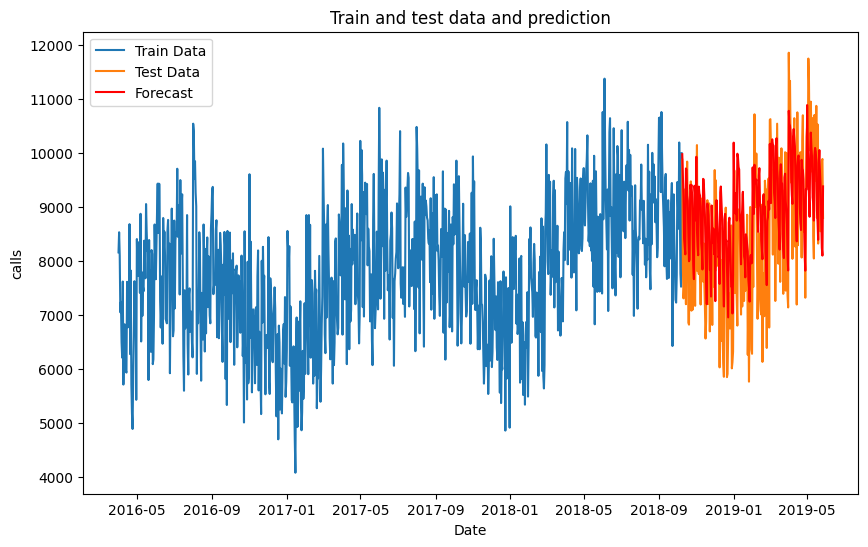

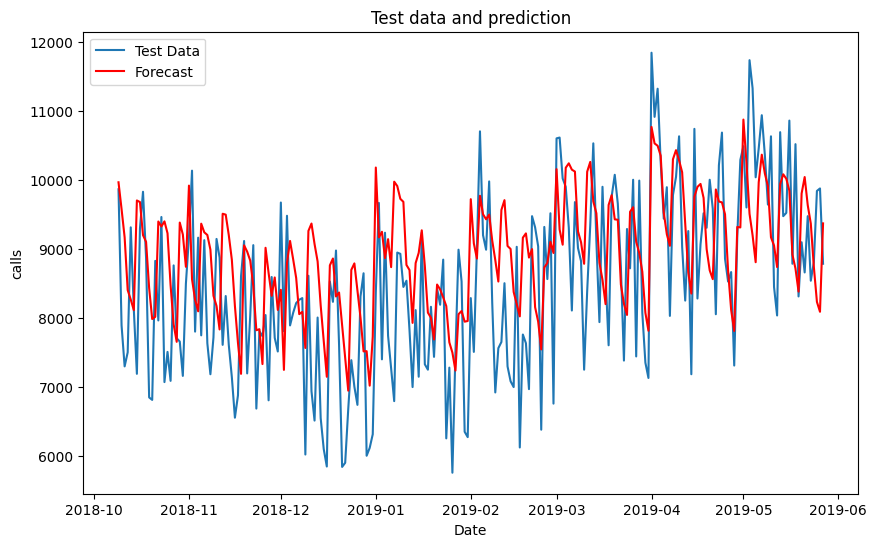

In [31]:
plt.figure(figsize=(10, 6))
plt.plot(X_train.index, y_train, label='Train Data')
plt.plot(X_test.index, y_test, label='Test Data')
plt.plot(X_test.index, y_pred_best, label='Forecast', color='red')
plt.title('Train and test data and prediction')
plt.xlabel('Date')
plt.ylabel(target_column)
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(X_test.index, y_test, label='Test Data')
plt.plot(X_test.index, y_pred_best, label='Forecast', color='red')
plt.title('Test data and prediction')
plt.xlabel('Date')
plt.ylabel(target_column)
plt.legend()
plt.show()




In [32]:
top_features = [features[i] for i in indices][-8:]

top_features.reverse()

display(top_features)

#overwrite top_features

#top_features = ["week_of_year", "tmax", "day_of_month", "tavg", "tmin", "unix_ts_date", "day_of_year", "day_of_week"]

#top_features = ["day_of_year", "day_of_week", "day_of_month", "week_of_year", "tmin", "tmax", "tavg", "n_duty"]


#top_features = ["day_of_year", "day_of_week", "day_of_month", "week_of_year", "tmin", "tmax", "tavg"] ## 22.7

#top_features = ["day_of_year", "day_of_week", "day_of_month", "week_of_year"] #24.8


#top_features = ["day_of_week",  "week_of_year"] #24.8

#top_features = ["unix_ts_date"]

['unix_ts_date', 'day_of_year', 'day_of_month', 'day_of_week']

# Modell mit weniger Features (nur die wichtigsten)

In [33]:
additional_columns = ["n_sick", "n_sby"]

X = df[top_features + additional_columns ]
y = df[target_column]

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

best_model.fit(X_train[top_features], y_train)

y_pred_best = best_model.predict(X_test[top_features])

mae = mean_absolute_error(y_test, y_pred_best)
mse = mean_squared_error(y_test, y_pred_best)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_best)
mape = mean_absolute_percentage_error(y_test, y_pred_best)

print(f'MAPE: {mape}, MAE: {mae}, MSE: {mse}, RMSE: {rmse}, R2: {r2}')


MAPE: 0.12707537730435328, MAE: 994.5646302289985, MSE: 1417735.992165969, RMSE: 1190.6871932484908, R2: 0.15472383469336426


In [34]:
result_df = X_test.copy(deep=True)

result_df = result_df.join(pd.DataFrame(y_test), how="left")
result_df["pred_sby_need"] = y_pred_best

display(calculate_custom_personal_metrics(result_df, "sby_need", "pred_sby_need", print_results=False))

plt.figure(figsize=(10, 6))
plt.plot(X_train.index, y_train, label='Train Data')
plt.plot(X_test.index, y_test, label='Test Data')
plt.plot(X_test.index, y_pred_best, label='Forecast', color='red')
plt.title('Train and test data and prediction')
plt.xlabel('Date')
plt.ylabel(target_column)
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(X_test.index, y_test, label='Test Data')
plt.plot(X_test.index, y_pred_best, label='Forecast', color='red')
plt.title('Test data and prediction')
plt.xlabel('Date')
plt.ylabel(target_column)
plt.legend()
plt.show()

KeyError: 'sby_need'

## LightGBM with custom loss

In [39]:
import lightgbm as lgb
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

# Daten vorbereiten
X = df[top_features]
y = df[target_column]

# Daten in Trainings- und Testsets aufteilen
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, shuffle=False)

# Definiere deine benutzerdefinierte Bewertungsmetrik
def custom_loss(y_pred, dataset):

    underestimation_penalty = 25
    overestimation_penalty = 1

    y_true = dataset.get_label()
    residual = (y_true - y_pred).astype("float")
    grad = np.where(residual > 0, -underestimation_penalty * residual, -overestimation_penalty * residual)  # Gradientenberechnung
    hess = np.where(residual > 0, underestimation_penalty, overestimation_penalty)  # Hesse-Matrix
    return grad, hess



# Erstelle das Dataset für LightGBM
train_data = lgb.Dataset(X_train, label=y_train)
valid_data = lgb.Dataset(X_test, label=y_test, reference=train_data)

# Definiere die Parameter
params = {
    'objective': 'regression',
    'metric': 'custom'
}

# Trainiere das Modell
bst = lgb.train(params, train_data, fobj=custom_loss, valid_sets=[train_data]) # für fobj LightGBM gedwongraded auf Version 3.2.1

# Vorhersagen machen
y_pred_best = bst.predict(X_test)

# Metriken berechnen
mae = mean_absolute_error(y_test, y_pred_best)
mse = mean_squared_error(y_test, y_pred_best)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_best)
mape = mean_absolute_percentage_error(y_test, y_pred_best)

print(f'MAPE: {mape}, MAE: {mae}, MSE: {mse}, RMSE: {rmse}, R2: {r2}')

[LightGBM] [Warning] Using self-defined objective function
[LightGBM] [Warning] Auto-choosing col-wise multi-threading, the overhead of testing was 0.032653 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 549
[LightGBM] [Info] Number of data points in the train set: 806, number of used features: 4
[LightGBM] [Warning] Using self-defined objective function
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain:

array([ 9188.67823943,  9092.71087933,  9954.62909247,  9659.42052814,
        9656.17120753,  9373.3846553 ,  9149.76827057,  8778.66120572,
        8477.69851569,  9120.09295476,  9163.67227333,  9191.92585299,
        8951.76462068,  8988.7279872 ,  8667.3154044 , 10024.3374112 ,
       11005.1606218 , 10845.0032631 , 10963.55871014, 10701.8758801 ,
        9999.63208887,  9531.68395365,  9146.95408012, 10110.77791883,
        9952.5369194 , 10070.80944845,  9914.97474791,  9899.03767178,
        9215.21363334,  9242.78837739, 10007.34882577,  9980.42724599,
        9929.75644687,  9499.5146026 ,  9362.81181115,  9126.65068986,
        8986.9700916 ,  9317.56381585,  8994.48315792,  8984.9137617 ,
        9088.13614352,  9022.39525835,  8669.20972402,  8773.06555725,
        9147.91387923,  9040.30592872, 11069.0110445 , 10860.69183069,
       10456.00843148,  9845.52440241,  9779.70720515, 10497.98053198,
       10299.26124109, 10074.57250831,  9670.72956706,  9616.48180701,
      

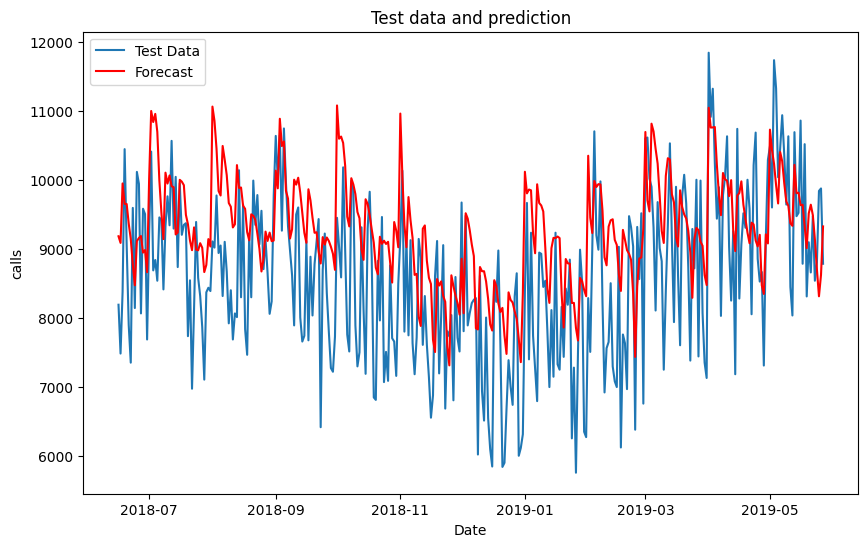

In [40]:
result_df = X_test.copy(deep=True)

display(y_pred_best)

result_df = result_df.join(pd.DataFrame(y_test), how="left")

#Werte kleiner 0 auf 0 setzen
y_pred_best[y_pred_best < 0] = 0

result_df["pred_sby_need"] = y_pred_best

#display(calculate_custom_personal_metrics(result_df, "sby_need", "pred_sby_need", print_results=False))



plt.figure(figsize=(10, 6))
plt.plot(X_test.index, y_test, label='Test Data')
plt.plot(X_test.index, result_df["pred_sby_need"], label='Forecast', color='red')
plt.title('Test data and prediction')
plt.xlabel('Date')
plt.ylabel(target_column)
plt.legend()
plt.show()

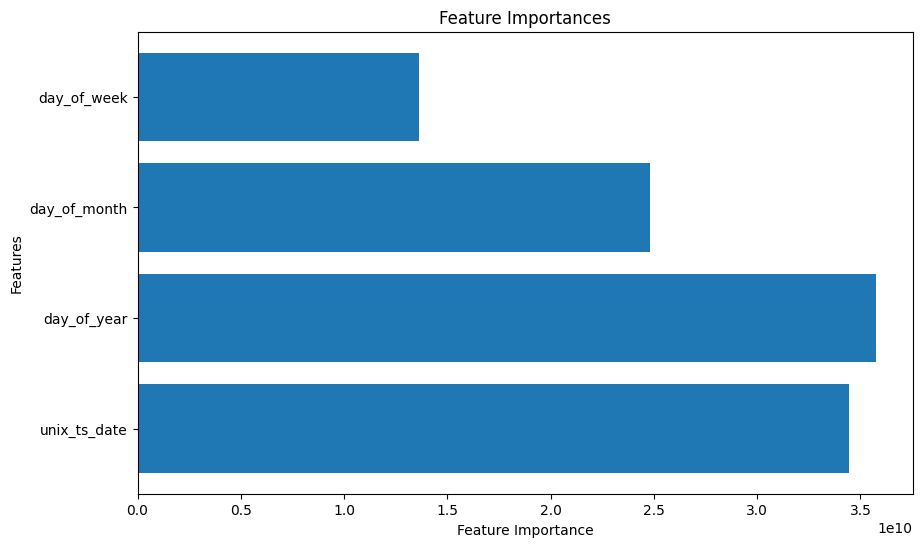

In [41]:
# Feature Importances extrahieren und plotten
importance = bst.feature_importance(importance_type='gain')
feature_names = X_train.columns

# Plotten der Feature Importances
plt.figure(figsize=(10, 6))
plt.barh(feature_names, importance)
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.title('Feature Importances')
plt.show()

# Prediction Test

In [ ]:
validation_df = pd.merge(X_test, y_test, left_index=True, right_index=True)

validation_df = validation_df.rename(columns={target_column : "orig_" + target_column})

display(validation_df)

,unix_ts_date,day_of_year,day_of_month,day_of_week,orig_sby_need
date,,,,,
2018-06-16,1529107200,167,16,5,0.0
2018-06-17,1529193600,168,17,6,0.0
2018-06-18,1529280000,169,18,0,0.0
2018-06-19,1529366400,170,19,1,276.0
2018-06-20,1529452800,171,20,2,2.0
...,...,...,...,...,...
2019-05-23,1558569600,143,23,3,0.0
2019-05-24,1558656000,144,24,4,0.0
2019-05-25,1558742400,145,25,5,46.0


In [ ]:
validation_df[target_column] = best_model.predict(validation_df[top_features])
display(validation_df)

,day_of_year,day_of_week,day_of_month,week_of_year,orig_sby_need,sby_need
date,,,,,,
2018-06-16,167,5,16,24,0.0,16.528190
2018-06-17,168,6,17,24,0.0,8.250631
2018-06-18,169,0,18,25,0.0,41.781285
2018-06-19,170,1,19,25,276.0,33.503726
2018-06-20,171,2,20,25,2.0,25.226168
...,...,...,...,...,...,...
2019-05-23,143,3,23,21,0.0,11.154727
2019-05-24,144,4,24,21,0.0,2.877169
2019-05-25,145,5,25,21,146.0,-5.400389


# Berechnen von n_sby aus Calls

In [22]:
validation_df = validation_df.rename(columns={"sby_need" : "orig_sby_need"})

In [23]:
validation_df["total_personal"] = validation_df.apply(lambda row: (row.calls / 5), axis=1)
validation_df["total_personal_based_on_orig_calls"] = validation_df.apply(lambda row: (row.orig_calls / 5), axis=1)

AttributeError: 'Series' object has no attribute 'calls'

In [ ]:
validation_df.describe()

,day_of_year,day_of_week,day_of_month,week_of_year,orig_sby_need,orig_sby_need
count,346.000000,346.000000,346.000000,346.000000,346.000000,346.000000
mean,184.427746,3.005780,15.895954,26.684971,37.442197,29.730605
std,108.188117,2.010111,8.729801,15.392513,79.115937,8.877856
min,1.000000,0.000000,1.000000,1.000000,0.000000,12.179517
25%,87.250000,1.000000,8.000000,13.000000,0.000000,22.209716
50%,192.500000,3.000000,16.000000,28.000000,0.000000,29.449718
75%,278.750000,5.000000,23.000000,40.000000,28.750000,37.235187
max,365.000000,6.000000,31.000000,52.000000,455.000000,47.029408


In [ ]:
validation_df["sby_need_new"] = validation_df.apply(lambda row: row.total_personal - row.n_duty + row.n_sby , axis=1)
validation_df["sby_need_based_on_orig_calls"] = validation_df.apply(lambda row: row.total_personal_based_on_orig_calls - row.n_duty + row.n_sby, axis=1)

validation_df["sby_need_diff"] = validation_df.apply(lambda row:  row.sby_need_new - row.orig_sby_need, axis=1)

AttributeError: 'Series' object has no attribute 'total_personal'

In [ ]:
display(validation_df)

,day_of_year,day_of_week,day_of_month,week_of_year,orig_sby_need,orig_sby_need
date,,,,,,
2018-06-16,167,5,16,24,0.0,29.378421
2018-06-17,168,6,17,24,0.0,28.374045
2018-06-18,169,0,18,25,0.0,27.369669
2018-06-19,170,1,19,25,276.0,26.365293
2018-06-20,171,2,20,25,2.0,25.360917
...,...,...,...,...,...,...
2019-05-23,143,3,23,21,0.0,21.909834
2019-05-24,144,4,24,21,0.0,20.905458
2019-05-25,145,5,25,21,46.0,19.901082


In [ ]:
validation_df[["orig_sby_need", "sby_need_new", "sby_need_based_on_orig_calls"]]

KeyError: "['sby_need_new', 'sby_need_based_on_orig_calls'] not in index"

In [ ]:
display(validation_df.sort_values("sby_need_diff", ascending=False))

,is_weekend,week_of_year,is_holiday,day_of_week,date,n_sick,orig_sby_need,n_sby,n_duty,orig_calls,calls,total_personal,total_personal_based_on_orig_calls,sby_need_new,sby_need_based_on_orig_calls,sby_need_diff
1004,False,1,False,0,2018-12-31,75,0.0,90,1900,6318.0,8241.896822,1648.379364,1263.6,-161.620636,-546.4,-161.620636
1011,False,2,False,0,2019-01-07,78,0.0,90,1900,6798.0,8238.761796,1647.752359,1359.6,-162.247641,-450.4,-162.247641
1018,False,3,False,0,2019-01-14,75,0.0,90,1900,8118.0,8235.626771,1647.125354,1623.6,-162.874646,-186.4,-162.874646
1025,False,4,False,0,2019-01-21,72,0.0,90,1900,8430.0,8232.491745,1646.498349,1686.0,-163.501651,-124.0,-163.501651
1032,False,5,False,0,2019-01-28,80,0.0,90,1900,8994.0,8229.356719,1645.871344,1798.8,-164.128656,-11.2,-164.128656
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1065,True,9,False,5,2019-03-02,60,284.0,90,1900,10620.0,7456.274090,1491.254818,2124.0,-318.745182,314.0,-602.745182
1097,False,14,False,2,2019-04-03,79,445.0,90,1900,11328.0,7993.330492,1598.666098,2265.6,-211.333902,455.6,-656.333902
1095,False,14,False,0,2019-04-01,85,555.0,90,1900,11850.0,8201.141487,1640.228297,2370.0,-169.771703,560.0,-724.771703
1128,True,18,False,5,2019-05-04,66,433.0,90,1900,11334.0,7428.058858,1485.611772,2266.8,-324.388228,456.8,-757.388228


In [ ]:
# validation_df["sby_need"] = validation_df.apply(lambda row: (row.total_personal - (row.n_duty + row.n_sick)), axis=1)

## Single prediction

In [ ]:
predict_data = pd.DataFrame([{
        'month' : 9,
        'day_of_week' : 3,
        'season' : 3,
        'n_sby_ma_35_lag_28' : 67,
        'day_of_year' : 266,
    }])


best_model.predict(predict_data)

ValueError: The feature names should match those that were passed during fit.
Feature names unseen at fit time:
- day_of_year
- month
- n_sby_ma_35_lag_28
- season
Feature names seen at fit time, yet now missing:
- is_holiday
- is_weekend
- week_of_year


# Export model

In [ ]:
import joblib

# Modell speichern
joblib.dump(best_model, '../../app/models/readiness_model.pkl')

['../../app/models/readiness_model.pkl']

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)